#**Ground Station Link Budget 2026-2027**

**v2 changes (review fixes + roof GS architecture)**

Bug fixes
- `prx_dBm` takes the frequency as an argument. Before, it was hard-wired to 438.1 MHz, so the SDR (2.427 GHz) results had 14.9 dB too little path loss.
- S-band Monte Carlo: every randomized term is now passed into the link equation (`tx_gain` and `atm` were drawn but never used). The broken duplicate that used UHF specs and subtracted cable loss twice is gone.
- Doppler was in Hz but labeled kHz.
- Random losses are clipped at 0 dB so they can't act as gain.
- One Earth radius (6371 km) everywhere.

Model changes
- UHF GS: roof chain (short coax, BPF, two T/R switches, LNA, 7025PA with a 10 dB drive pad), with a cascaded system temperature instead of a flat 290 K.
- UHF polarization: 3 dB nominal. The Monte Carlo can draw a random linear mismatch angle (single Yagi) or a fixed ~3 dB (crossed Yagi).
- The tumbling satellite dipole is now the high-uncertainty antenna in both directions.
- S-band: DVB-S2 downlink only (RP2350 + AFE7071 + PA), DVB-S2 Es/N0 thresholds, PA power variable (2 W baseline), best-MODCOD rate table, and PA-power-needed table. The SX1280 LoRa S-band and SDR uplink cases were removed (the satellite has no S-band receiver).
- Dropped the SF12 "−136 dBm" datasheet override; the noise-based formula gives −137 dBm.

Still PLACEHOLDER: BPF (in-band loss and passband, see warning), LNAs, T/R switches, UHF Yagi gain and polarization, roof antenna noise temperature, satellite S-band antenna and losses, E200 noise figure, DVB-S2 implementation loss.


# Link Budget

$$
P_{rx} =
P_{tx} - L_{\rm tx\,cable}
+ G_{\rm tx}
-\mathrm{FSPL}(f,R)
- L_{\rm atm} - L_{\rm pol} - L_{\rm point}
+ G_{\rm rx}
- L_{\rm rx\,cable}
$$

#Free space path loss:
$$
\mathrm{FSPL\,[dB]} \;=\; 20\log_{10}\!\left(\frac{4\pi\,d\,f}{c}\right)
$$

#Noise floor:
$$
N_{\,[dBm]} = 10\log_{10}\!\big(k\,T_{\rm sys}\,B\big) + 30 + NF
$$

#Signal-to-Noise Ratio:
$$
\mathrm{SNR\,[dB]} = P_{\rm rx\,[dBm]} - N_{\,[dBm]}
$$
=
#Decode margin:
$$
\mathrm{Margin\,[dB]} = \mathrm{SNR\,[dB]} - \mathrm{SNR}_{\rm req\,[dB]}
$$

#Polarization Loss:

Polarization mismatch loss can be expressed as:

$$
L_{\mathrm{pol}}
=
-10\log_{10}
\left(
|\hat{p}_T\cdot\hat{p}_R|^2
\right)
$$

For linear polarization with mismatch angle $\theta$:

$$
L_{\mathrm{pol}}
=
-10\log_{10}
\left(
\cos^2\theta
\right)
$$

For perfectly matched polarization:

$$
L_{\mathrm{pol}}=0\ \mathrm{dB}
$$

#Effective Isotropic Radiated Power:

The transmitter EIRP is:

$$
\boxed{
EIRP
=
P_T
-
L_{\mathrm{TX}}
+
G_T
}
$$

Then:

$$
P_R
=
EIRP
-
L_{\mathrm{FS}}
-
L_{\mathrm{atm}}
-
L_{\mathrm{pol}}
-
L_{\mathrm{point}}
+
G_R
-
L_{\mathrm{RX}}
$$


---

# Antenna Gain

For an aperture antenna:

$$
G
=
\eta
\frac{4\pi A}{\lambda^2}
$$

where:

- $\eta$ = antenna efficiency
- $A$ = physical aperture
- $\lambda$ = wavelength

In dBi:

$$
G_{\mathrm{dBi}}
=
10\log_{10}(G)
$$

## **`Background:`**
The effects of attenuation by atmospheric gases may be neglected for frequencies under 10 GHz. The communication architecture is only using S-band for downlink only and UHF for TT&C downlink and up link. Recommendations made by the ITU-R P.618-14 08/2023 iteration.

**Setup:**


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Units
GHz, MHz, kHz, km = 1e9, 1e6, 1e3, 1e3

C   = 299_792_458.0       # speed of light [m/s]
MU  = 3.986004418e14      # Earth gravitational parameter [m^3/s^2]
R_EARTH_KM = 6371.0       # mean Earth radius, used everywhere (was 6378 in one place, 6371 in another)
R_EARTH_M  = R_EARTH_KM*km
T0  = 290.0               # reference temperature [K]
KT0_DBM_PER_HZ = -174.0   # k*T0 at 290 K [dBm/Hz] (this is kT0, not Boltzmann's k)

# Carrier frequencies
f_Hz_UHF = 438.1*MHz      # UHF TT&C, both directions
f_Hz_S   = 2.427*GHz      # S-band, satellite -> GS only


In [ ]:
#General Equations and Conversions

def db(x):  return 10*np.log10(x)                          # linear -> dB
def lin(x): return 10**(np.asarray(x, dtype=float)/10)     # dB -> linear

def fspl_db(d_m, f_hz):
    """Free space path loss [dB]."""
    return 20*np.log10(4*np.pi*d_m*f_hz/C)

def therm_noise_dbm(T_sys_K, B_Hz):
    """Noise power kTB [dBm]."""
    return KT0_DBM_PER_HZ + 10*np.log10(T_sys_K/T0) + 10*np.log10(B_Hz)

# ---- Noise temperature helpers ----
def nf_to_te(nf_dB):
    """Noise figure [dB] -> equivalent noise temperature [K]."""
    return T0*(lin(nf_dB) - 1)

def tsys_at_lna_input(T_ant_K, pre_loss_dB, lna_nf_dB, lna_gain_dB, post_loss_dB, rx_nf_dB):
    """System noise temperature referred to the LNA input [K].
    Chain: antenna -> passive loss (pre_loss) -> LNA -> passive loss (post_loss) -> receiver.
    The pre-LNA loss is ALSO subtracted from the signal (rx_loss_dB), so signal and noise
    are both referenced at the LNA input."""
    L_pre   = lin(pre_loss_dB)
    T_in    = T_ant_K/L_pre + T0*(1 - 1/L_pre)                # attenuated sky/ground noise + loss noise
    L_post  = lin(post_loss_dB)
    Te_post = T0*(L_post - 1) + L_post*nf_to_te(rx_nf_dB)    # post-LNA loss + receiver
    return T_in + nf_to_te(lna_nf_dB) + Te_post/lin(lna_gain_dB)

# Required SNR per spreading factor (demod limit) https://www.thethingsnetwork.org/docs/lorawan/rssi-and-snr/
LORA_SNR = {6: -5, 7: -7.5, 8: -10, 9: -12.5, 10: -15, 11: -17.5, 12: -20}
def lora_demod_snr(sf): return LORA_SNR[int(sf)]

def lora_bitrate_bps(sf, bw_hz=125e3, cr=4/5):
    return sf*(bw_hz/2**sf)*cr

# Our testing altitudes / elevations
altitudes_km      = [400, 600, 800, 1000]
elevations_degree = [0, 5, 10, 20, 30, 45, 60, 90]

def slant_range_km(alt_km, elev_deg):
    e = np.radians(elev_deg)
    r = R_EARTH_KM
    return np.sqrt((r + alt_km)**2 - (r*np.cos(e))**2) - r*np.sin(e)

def doppler_max_hz(alt_km, f_hz):
    """Peak Doppler for an overhead pass (at the horizon), ignoring Earth rotation. Returns Hz."""
    a = R_EARTH_M + alt_km*km
    v = np.sqrt(MU/a)
    return f_hz*(v/C)*(R_EARTH_M/a)

def prx_dBm(alt_km, elev_deg, s, f_hz, **override):
    """Received power [dBm] for link spec `s` at frequency f_hz.
    Any spec key can be overridden (the Monte Carlo passes arrays this way).
    Frequency is now an explicit argument -- previously it was hard-wired to UHF."""
    p = {**s, **override}
    d_m = slant_range_km(alt_km, elev_deg)*km
    return (p["tx_power_dBm"] - p["tx_loss_dB"] + p["tx_gain_dBi"]
            - fspl_db(d_m, f_hz)
            - p["L_atm_dB"] - p["L_pol_dB"] - p["L_point_dB"]
            + p["rx_gain_dBi"] - p["rx_loss_dB"])

def loss_sample(rng, nominal_dB, std_dB, n):
    """Random loss that can't go below 0 dB (a loss is never a gain)."""
    return np.clip(nominal_dB + rng.normal(0, std_dB, n), 0, None)


Need to knows:

####Coolio Resources:
https://www.itu.int/rec/R-REC-P.618-14-202308-I/en

https://www.sm5bsz.com/antennas/cpudes01.htm

https://www.satnow.com/calculators/satellite-slant-range-calculator

https://ieeexplore.ieee.org/document/9133336

https://rftools.io/blog/satellite-link-budget-itu-r-propagation/




Uplink:

**UHF Architecture Uplink and Downlink (Durand roof)**:

```
TX:  RFM96W -> SW2 -> 10 dB pad -> 7025PA (25 W) -> SW1 -> BPF -> coax -> Yagi
RX:  Yagi -> coax -> BPF -> SW1 -> LNA -> SW2 -> RFM96W
SAT: RFM98PW (1 W) <-> dipole
```

Hardware notes:
- 7025PA drive: 10 mW (+10 dBm) for rated 25 W, 50 mW (+17 dBm) saturated, **100 mW (+20 dBm) absolute max**. The RFM96W can output +20 dBm, so a fixed 10 dB pad keeps the PA safe no matter what the firmware sets. LoRa is constant-envelope, so running the PA toward saturation (~40 W) is fine if you want the extra ~2 dB.
- SW1 and the BPF carry the full 25–40 W on transmit: both must be rated for it.
- SW1 isolation must keep the PA leakage below the LNA's max input. Sequence on TX: switches -> PTT-L -> RF; on RX: RF off -> PTT off -> switches.
- PA needs 13.8 V at up to 10 A.

Values marked PLACEHOLDER are waiting on the BPF, LNA and switch part numbers.


In [ ]:
#UHF Setup

GS_UHF = dict(
    yagi_gain_dBi   = 10.0,     # CONFIRM model -- old notebook used 10 (UL) and 7 (DL) for the same Yagi
    yagi_pol        = "linear", # "linear" (single Yagi) or "circular" (crossed Yagi)
    coax_dB         = 0.2,      # ~2 m LMR-400 @ 438 MHz (~0.09 dB/m) + connectors
    bpf_IL_dB       = 1.0,      # PLACEHOLDER: in-band insertion loss (BPF is in both TX and RX paths)
    bpf_passband_MHz = (450.0, 460.0),  # PolyPhaser RRF-450-NFM-L -- does NOT cover 438.1 MHz, see warning
    sw1_IL_dB       = 0.2,      # PLACEHOLDER: antenna-side T/R switch (sees full PA power)
    sw2_IL_dB       = 0.2,      # PLACEHOLDER: module-side T/R switch
    lna_nf_dB       = 1.0,      # PLACEHOLDER
    lna_gain_dB     = 20.0,     # PLACEHOLDER
    rfm_nf_dB       = 6.0,      # RFM96W (SX1276-class) receiver NF, approx
    rfm_tx_dBm      = 20.0,     # RFM96W PA_BOOST max output
    pa_drive_pad_dB = 10.0,     # fixed attenuator between SW2 and the PA
    pa_gain_dB      = 34.0,     # 7025PA: 10 mW in -> 25 W out (linear)
    pa_sat_dBm      = 46.0,     # 7025PA: >40 W saturated (typ)
    T_ant_K         = 290.0,    # PLACEHOLDER: Yagi near the horizon sees ground + campus RFI; measure on the roof
)

SAT_UHF = dict(
    tx_power_dBm = 30.0,   # RFM98PW (1 W)
    ant_gain_dBi = 2.0,    # dipole (estimate)
    loss_dB      = 0.2,    # onboard/internal loss -- measure once boards exist
    nf_dB        = 6.0,    # satellite receiver NF (SX127x-class)
)

def gs_uhf_tx_power_dBm(g=None):
    """RFM96W -> SW2 -> pad -> 7025PA. Returns (PA output dBm, PA drive dBm) and checks drive limits."""
    g = g or GS_UHF
    drive = g["rfm_tx_dBm"] - g["sw2_IL_dB"] - g["pa_drive_pad_dB"]
    if drive > 20.0:
        raise ValueError(f"PA drive {drive:.1f} dBm exceeds the 7025PA 100 mW (+20 dBm) max")
    if drive > 17.0:
        print(f"Warning: PA drive {drive:.1f} dBm is past the 50 mW saturation point")
    return min(drive + g["pa_gain_dB"], g["pa_sat_dBm"]), drive

def build_uhf_specs(g=None, sat=None, SF=7):
    g, sat = g or GS_UHF, sat or SAT_UHF
    pa_out, drive = gs_uhf_tx_power_dBm(g)
    gs_passive = g["coax_dB"] + g["bpf_IL_dB"] + g["sw1_IL_dB"]   # between antenna and PA / LNA
    common = dict(
        BW_Hz      = 125e3,
        SF         = SF,
        L_atm_dB   = 0.3,
        L_pol_dB   = 3.0,   # median for linear Yagi vs tumbling dipole (random angle); fixed 3 dB if GS is circular
        L_point_dB = 4.0,
    )
    ul = dict(common,
        tx_power_dBm = pa_out,
        tx_loss_dB   = gs_passive,
        tx_gain_dBi  = g["yagi_gain_dBi"],
        rx_gain_dBi  = sat["ant_gain_dBi"],
        rx_loss_dB   = sat["loss_dB"],
        NF_dB        = sat["nf_dB"],
    )
    dl = dict(common,
        tx_power_dBm = sat["tx_power_dBm"],
        tx_loss_dB   = sat["loss_dB"],
        tx_gain_dBi  = sat["ant_gain_dBi"],
        rx_gain_dBi  = g["yagi_gain_dBi"],
        rx_loss_dB   = gs_passive,             # pre-LNA loss
        T_sys_K      = tsys_at_lna_input(g["T_ant_K"], gs_passive, g["lna_nf_dB"],
                                         g["lna_gain_dB"], g["sw2_IL_dB"], g["rfm_nf_dB"]),
    )
    return ul, dl, drive

lo, hi = GS_UHF["bpf_passband_MHz"]
if not (lo <= f_Hz_UHF/MHz <= hi):
    print(f"WARNING: {f_Hz_UHF/MHz:.1f} MHz is outside the BPF passband ({lo:g}-{hi:g} MHz). "
          "bpf_IL_dB is NOT valid here -- the real loss will be much higher.")

spec_UL, spec_DL, pa_drive_dBm = build_uhf_specs()
eirp = spec_UL["tx_power_dBm"] - spec_UL["tx_loss_dB"] + spec_UL["tx_gain_dBi"]
print(f"PA drive {pa_drive_dBm:.1f} dBm -> PA out {spec_UL['tx_power_dBm']:.1f} dBm -> GS EIRP {eirp:.1f} dBm")
print(f"GS UHF T_sys at LNA input = {spec_DL['T_sys_K']:.0f} K")


PA drive 9.8 dBm -> PA out 43.8 dBm -> GS EIRP 52.4 dBm
GS UHF T_sys at LNA input = 374 K


In [ ]:
def sensitivity_UL_dBm(s=None):
    """Satellite receiver. Its antenna sees the Earth (~290 K), so kT0 + NF is a fair model."""
    s = s or spec_UL
    return KT0_DBM_PER_HZ + 10*np.log10(s["BW_Hz"]) + s["NF_dB"] + lora_demod_snr(s["SF"])

def sensitivity_DL_dBm(s=None, T_sys_K=None):
    """Ground station receiver, from the cascaded system temperature."""
    s = s or spec_DL
    T = s["T_sys_K"] if T_sys_K is None else T_sys_K
    return therm_noise_dbm(T, s["BW_Hz"]) + lora_demod_snr(s["SF"])

def margin_UL_dB(alt_km, elev_deg, s=None):
    s = s or spec_UL
    return prx_dBm(alt_km, elev_deg, s, f_Hz_UHF) - sensitivity_UL_dBm(s)

def margin_DL_dB(alt_km, elev_deg, s=None):
    s = s or spec_DL
    return prx_dBm(alt_km, elev_deg, s, f_Hz_UHF) - sensitivity_DL_dBm(s)


Monte Carlo Simulation!

- TX power: datasheets only give typical values.
- Satellite antenna gain: the dipole tumbles, so it gets the wide spread (3 dB). The GS Yagi gets a smaller spread (1 dB) for gain uncertainty.
- Polarization: with a single linear Yagi, the mismatch angle against the tumbling dipole (plus Faraday rotation at UHF) is random, so the loss is drawn from $-10\log_{10}(\cos^2\theta)$ with $\theta$ uniform, capped by the Yagi's cross-pol isolation. With a circular (crossed) Yagi it's a steady ~3 dB.
- Pointing: GS rotator/controller error. Clipped at 0 dB so a loss never becomes a gain.
- System temperature: only on the downlink, for the spread on the GS T_sys.


In [ ]:
#Ahoy! Monte Carlo Over here!

def sample_pol_loss_uhf(rng, n, mode, xpd_dB=20.0):
    if mode == "linear":
        th = rng.uniform(0, np.pi/2, n)   # random mismatch angle
        return np.clip(-10*np.log10(np.cos(th)**2 + 10**(-xpd_dB/10)), 0, None)
    if mode == "circular":
        return loss_sample(rng, 3.0, 0.5, n)
    raise ValueError(f"Invalid pol mode: {mode}")

def monte_carlo_margin(alt_km, elev_deg, link, n=50000, seed=0, pol_mode=None,
                       point_std_dB=5, sat_ant_std_dB=3.0, gs_ant_std_dB=1.0,
                       tsys_std_K=100.0, tx_power_std_dB=0.5):
    rng = np.random.default_rng(seed)
    if link not in ("UL", "DL"):
        raise ValueError(f"Invalid link: {link}")
    s = spec_UL if link == "UL" else spec_DL
    pol_mode = pol_mode or GS_UHF["yagi_pol"]

    sat_gain = SAT_UHF["ant_gain_dBi"] + rng.normal(0, sat_ant_std_dB, n)   # tumbling dipole
    gs_gain  = GS_UHF["yagi_gain_dBi"] + rng.normal(0, gs_ant_std_dB, n)
    ov = dict(
        tx_power_dBm = s["tx_power_dBm"] + rng.normal(0, tx_power_std_dB, n),
        L_pol_dB     = sample_pol_loss_uhf(rng, n, pol_mode),
        L_point_dB   = loss_sample(rng, s["L_point_dB"], point_std_dB, n),
        tx_gain_dBi  = gs_gain  if link == "UL" else sat_gain,
        rx_gain_dBi  = sat_gain if link == "UL" else gs_gain,
    )
    prx = prx_dBm(alt_km, elev_deg, s, f_Hz_UHF, **ov)

    if link == "UL":
        sens = sensitivity_UL_dBm(s)
    else:
        tsys = np.clip(s["T_sys_K"] + rng.normal(0, tsys_std_K, n), 50, None)
        sens = sensitivity_DL_dBm(s, T_sys_K=tsys)
    return prx - sens


In [ ]:
rows = []
for h in altitudes_km:
    rows.append(dict(
        alt_km          = h,
        UL_10deg        = margin_UL_dB(h, 10),
        UL_horizon      = margin_UL_dB(h, 0),
        DL_10deg        = margin_DL_dB(h, 10),
        DL_horizon      = margin_DL_dB(h, 0),
        doppler_UHF_kHz = doppler_max_hz(h, f_Hz_UHF)/kHz,   # was printed in Hz before
        doppler_S_kHz   = doppler_max_hz(h, f_Hz_S)/kHz,
    ))
df_uhf = pd.DataFrame(rows).round(1)
print("Deterministic UHF margins [dB] (LoRa SF%d)" % spec_UL["SF"])
print(df_uhf.to_string(index=False))


Deterministic UHF margins [dB] (LoRa SF7)
 alt_km  UL_10deg  UL_horizon  DL_10deg  DL_horizon  doppler_UHF_kHz  doppler_S_kHz
    400      23.0        18.9      14.1        10.0             10.5           58.4
    600      20.4        17.1      11.5         8.2             10.1           55.9
    800      18.7        15.8       9.8         6.9              9.7           53.6
   1000      17.3        14.8       8.4         5.9              9.3           51.5


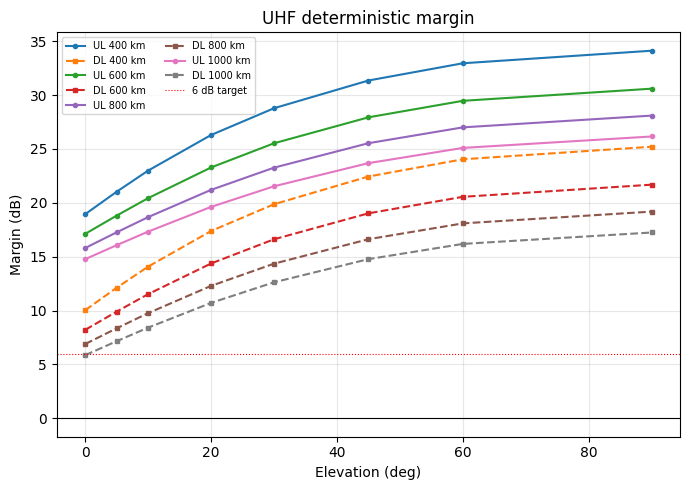

In [ ]:
fig, ax = plt.subplots(figsize=(7,5))

for h in altitudes_km:
    ax.plot(elevations_degree, [margin_UL_dB(h, e) for e in elevations_degree],
            marker="o", ms=3, label=f"UL {h} km")
    ax.plot(elevations_degree, [margin_DL_dB(h, e) for e in elevations_degree],
            marker="s", ms=3, ls="--", label=f"DL {h} km")

ax.axhline(0, color="k", lw=0.8)
ax.axhline(6, color="r", ls=":", lw=0.8, label="6 dB target")
ax.set_xlabel("Elevation (deg)"); ax.set_ylabel("Margin (dB)")
ax.set_title("UHF deterministic margin")
ax.legend(fontsize=7, ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


Coolio explanation of the KDE plot and implementation

https://seaborn.pydata.org/generated/seaborn.kdeplot.html


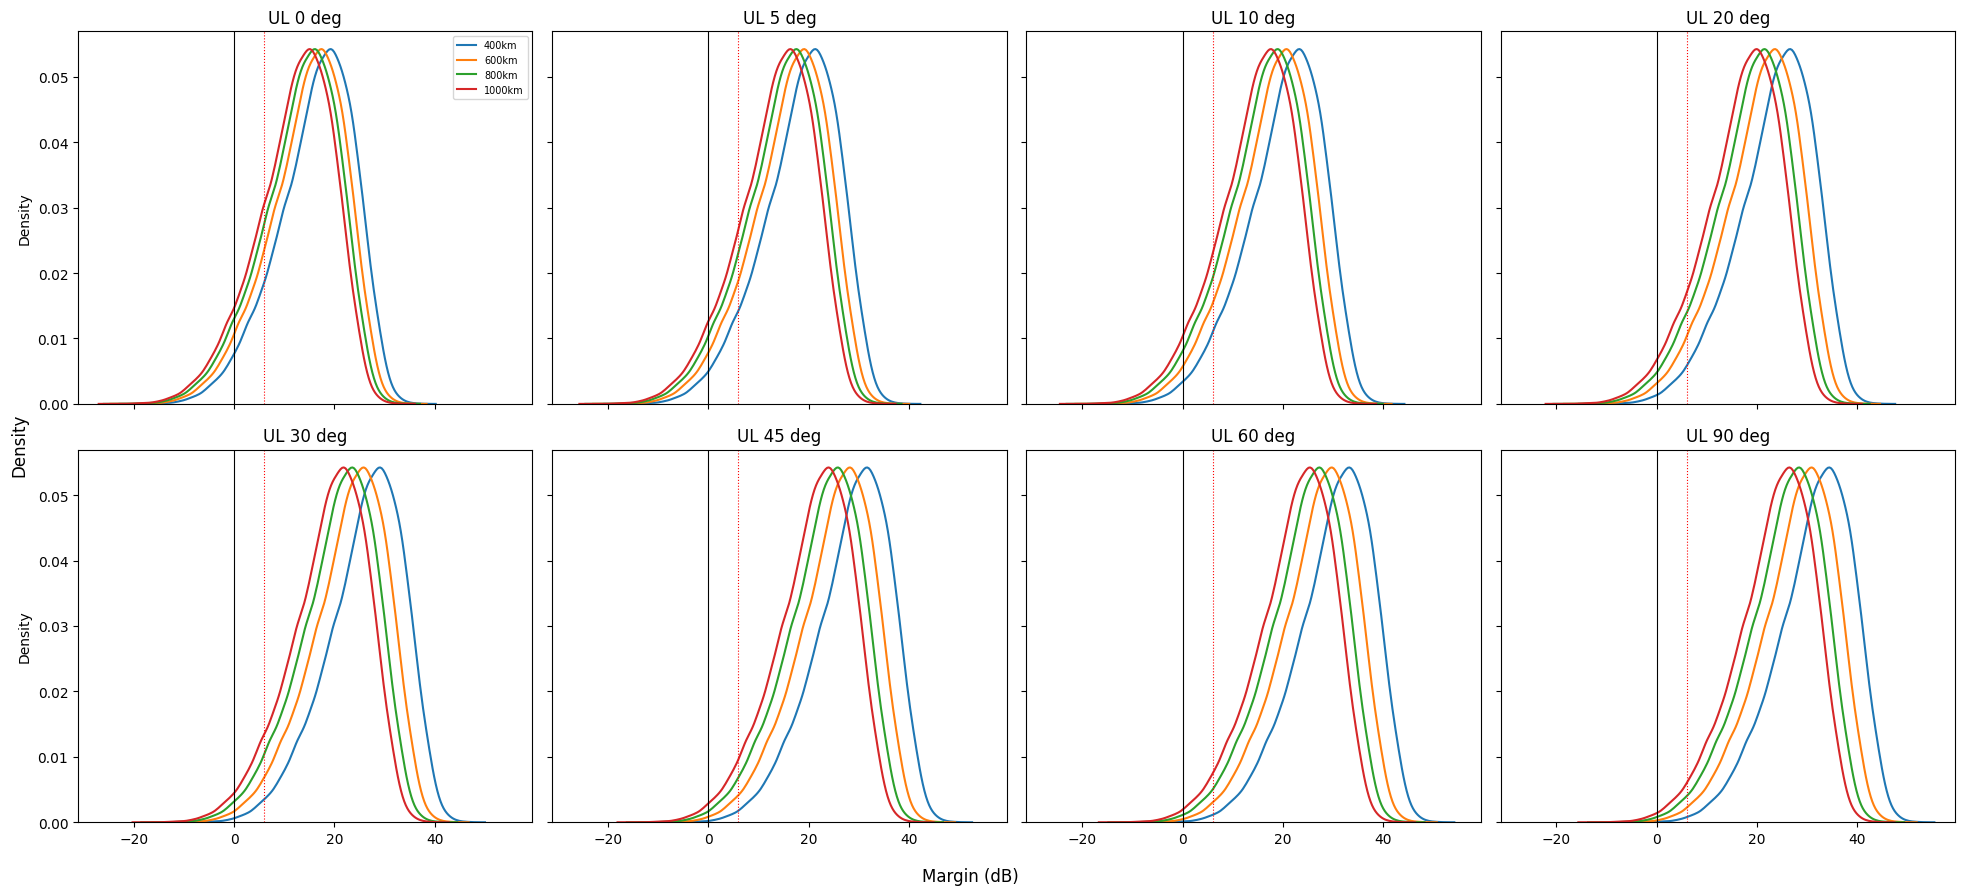

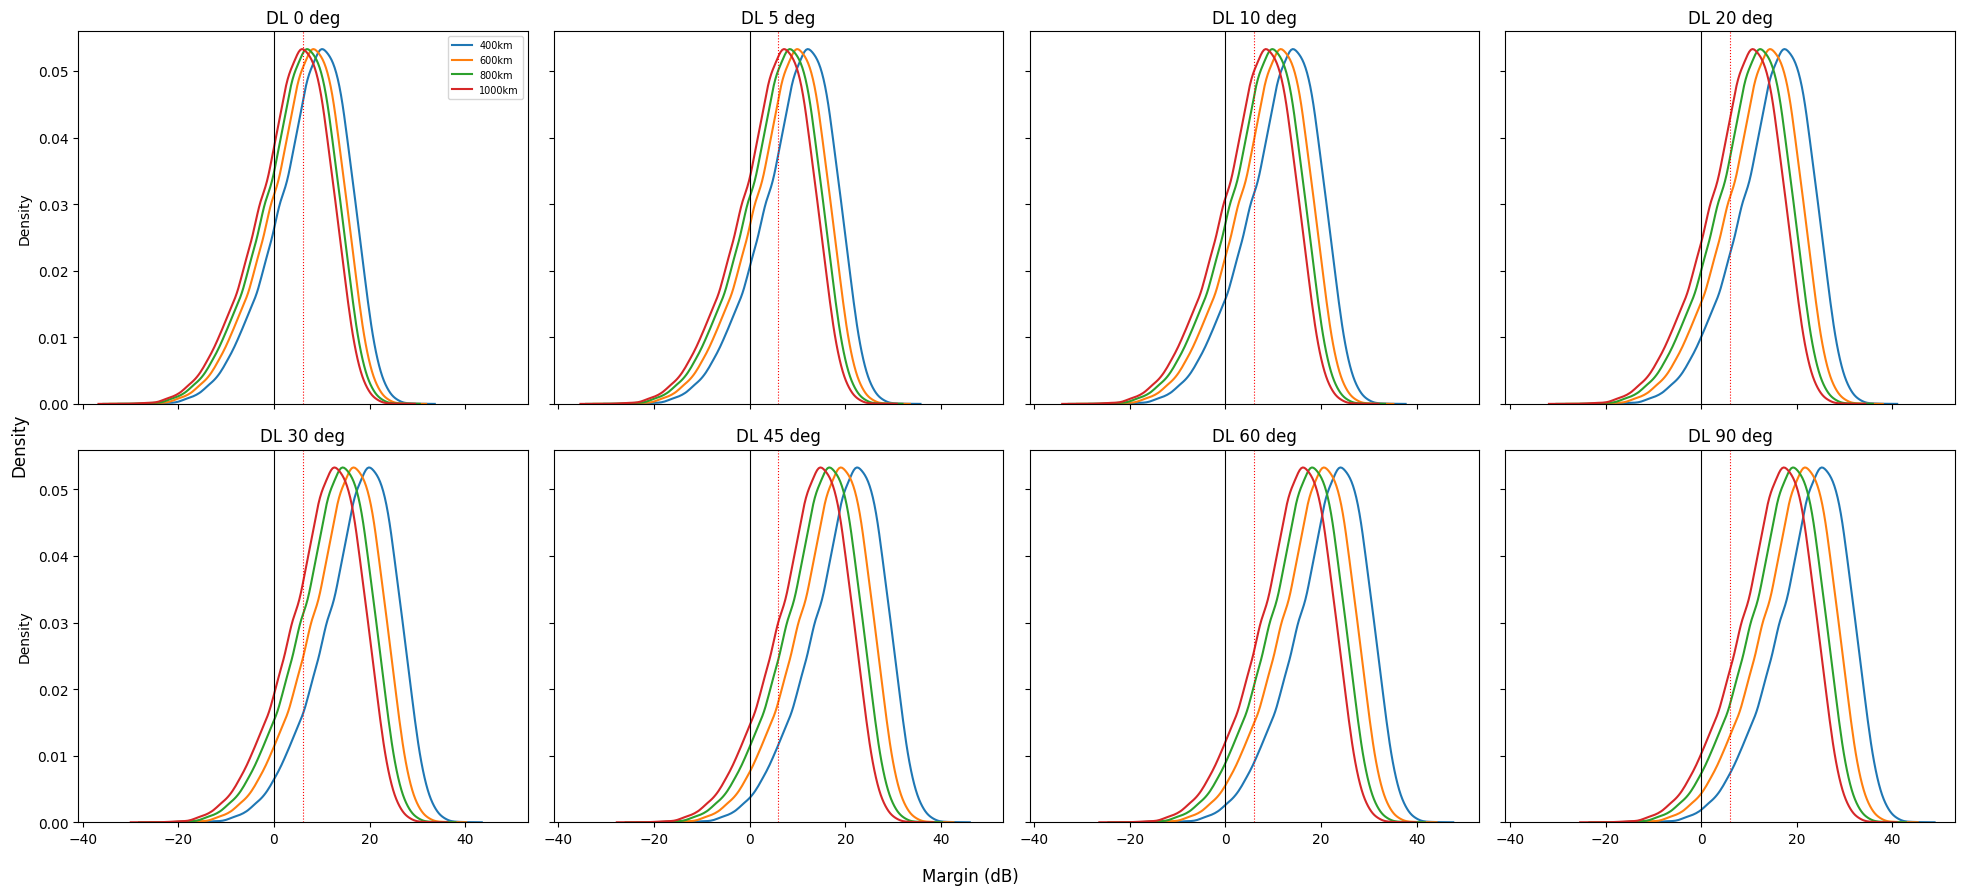

In [ ]:
def kde_grid(link, sf_label=""):
    n = len(elevations_degree)
    cols = 4
    nrows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(nrows, cols, figsize=(5*cols, 4.5*nrows), sharex=True, sharey=True)
    axes = axes.ravel()
    for i, elev in enumerate(elevations_degree):
        ax = axes[i]
        for h in altitudes_km:
            sns.kdeplot(monte_carlo_margin(h, elev, link), ax=ax, label=f"{h}km")
        ax.axvline(0, color="k", lw=0.8)
        ax.axvline(6, color="r", ls=":", lw=0.8)
        ax.set_title(f"{link} {elev} deg")
    for j in range(n, len(axes)):
        axes[j].axis("off")
    axes[0].legend(fontsize=7)
    fig.supxlabel("Margin (dB)"); fig.supylabel("Density")
    plt.tight_layout(); plt.show()

kde_grid("UL")
kde_grid("DL")


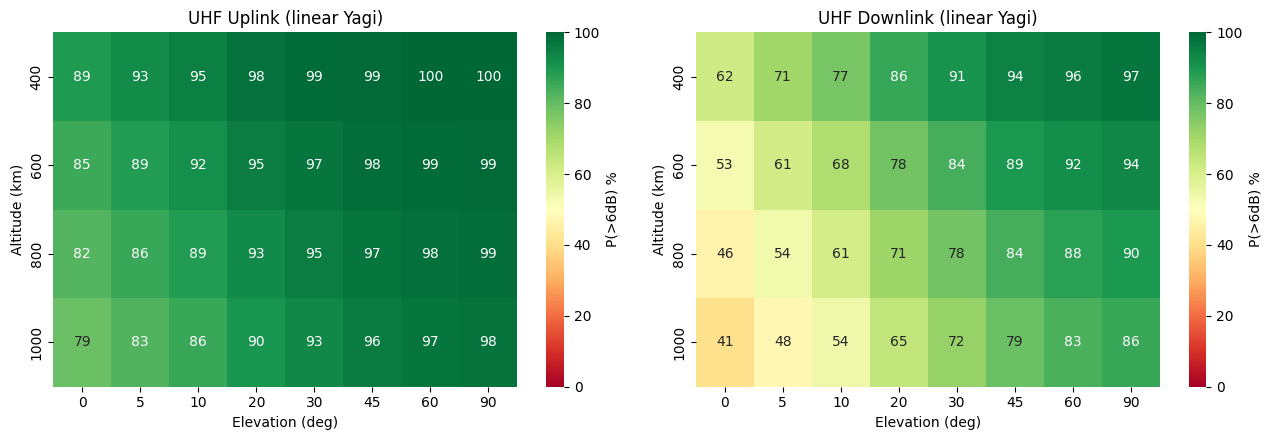

In [ ]:
def p_target_grid(altitudes, elevations, mc_func, target=6.0, **kwargs):
    grid = np.zeros((len(altitudes), len(elevations)))
    for i, h in enumerate(altitudes):
        for j, e in enumerate(elevations):
            m = mc_func(h, e, **kwargs)
            grid[i, j] = 100*(m > target).mean()
    return pd.DataFrame(grid, index=altitudes, columns=elevations)

def plot_heatmaps(dfs, titles, label="P(>6dB) %"):
    fig, axes = plt.subplots(1, len(dfs), figsize=(6.5*len(dfs), 4.5))
    axes = np.atleast_1d(axes)
    for ax, d, title in zip(axes, dfs, titles):
        sns.heatmap(d, annot=True, fmt=".0f", cmap="RdYlGn", vmin=0, vmax=100,
                    cbar_kws={"label": label}, ax=ax)
        ax.set_xlabel("Elevation (deg)"); ax.set_ylabel("Altitude (km)"); ax.set_title(title)
    plt.tight_layout(); plt.show()

pol = GS_UHF["yagi_pol"]
p6_ul = p_target_grid(altitudes_km, elevations_degree, monte_carlo_margin, link="UL")
p6_dl = p_target_grid(altitudes_km, elevations_degree, monte_carlo_margin, link="DL")
plot_heatmaps([p6_ul, p6_dl], [f"UHF Uplink ({pol} Yagi)", f"UHF Downlink ({pol} Yagi)"])


In [ ]:
print("Uplink P(margin > 6 dB) [%]")
print(p6_ul.round(1).to_string())
print("\nDownlink P(margin > 6 dB) [%]")
print(p6_dl.round(1).to_string())


Uplink P(margin > 6 dB) [%]
        0     5     10    20    30    45    60    90
400   89.1  92.5  95.1  97.7  98.8  99.5  99.7  99.8
600   85.4  88.9  91.7  95.4  97.2  98.5  99.0  99.3
800   82.0  85.7  88.7  92.8  95.4  97.2  98.1  98.6
1000  79.0  82.8  85.9  90.4  93.2  95.7  96.9  97.6

Downlink P(margin > 6 dB) [%]
        0     5     10    20    30    45    60    90
400   61.9  70.5  77.1  86.1  90.9  94.4  96.1  97.0
600   53.0  61.2  68.2  78.0  84.3  89.5  91.9  93.5
800   46.3  53.6  60.6  71.2  77.9  84.3  87.6  89.7
1000  40.6  47.5  53.9  64.8  72.3  79.3  83.2  85.8


In [ ]:
# Linear vs circular (crossed Yagi) GS antenna: same ~3 dB median loss, but linear has deep fades
rows = []
for mode in ("linear", "circular"):
    for link in ("UL", "DL"):
        m = monte_carlo_margin(600, 10, link, pol_mode=mode)
        rows.append(dict(gs_pol=mode, link=link, median_dB=np.median(m),
                         p5_dB=np.percentile(m, 5), P_gt_6dB=100*(m > 6).mean(), P_gt_0dB=100*(m > 0).mean()))
print("600 km, 10 deg elevation")
print(pd.DataFrame(rows).round(1).to_string(index=False))


600 km, 10 deg elevation
  gs_pol link  median_dB  p5_dB  P_gt_6dB  P_gt_0dB
  linear   UL       18.6    3.5      91.7      97.8
  linear   DL        9.9   -5.4      68.2      86.4
circular   UL       20.2   10.5      99.2     100.0
circular   DL       11.5    1.6      82.4      97.3


**What-if: parts not chosen yet.** Downlink margin (600 km, 10°) against BPF insertion loss and LNA noise figure, then against antenna noise temperature (campus RFI on the Durand roof). Every dB of BPF loss also comes straight off the uplink, since the BPF is in the TX path too.


In [ ]:
bpf_list = [0.5, 1.0, 2.0, 3.0]
nf_list  = [0.5, 1.0, 2.0, 3.0]
tab = pd.DataFrame(index=[f"BPF {b} dB" for b in bpf_list],
                   columns=[f"LNA NF {x} dB" for x in nf_list], dtype=float)
for b in bpf_list:
    for x in nf_list:
        _, dl, _ = build_uhf_specs(dict(GS_UHF, bpf_IL_dB=b, lna_nf_dB=x))
        tab.loc[f"BPF {b} dB", f"LNA NF {x} dB"] = margin_DL_dB(600, 10, dl)
print("UHF DL margin [dB] at 600 km / 10 deg")
print(tab.round(1).to_string())

print("\nAntenna noise temperature -> T_sys, DL margin at 600 km / 10 deg")
for Ta in [150, 290, 600, 1000, 2000]:
    _, dl, _ = build_uhf_specs(dict(GS_UHF, T_ant_K=Ta))
    print(f"  T_ant {Ta:5d} K -> T_sys {dl['T_sys_K']:6.0f} K, margin {margin_DL_dB(600, 10, dl):5.1f} dB")


UHF DL margin [dB] at 600 km / 10 deg
            LNA NF 0.5 dB  LNA NF 1.0 dB  LNA NF 2.0 dB  LNA NF 3.0 dB
BPF 0.5 dB           12.5           12.0           11.0           10.1
BPF 1.0 dB           12.0           11.5           10.5            9.6
BPF 2.0 dB           11.0           10.5            9.5            8.6
BPF 3.0 dB           10.0            9.5            8.5            7.6

Antenna noise temperature -> T_sys, DL margin at 600 km / 10 deg
  T_ant   150 K -> T_sys    273 K, margin  12.9 dB
  T_ant   290 K -> T_sys    374 K, margin  11.5 dB
  T_ant   600 K -> T_sys    599 K, margin   9.5 dB
  T_ant  1000 K -> T_sys    889 K, margin   7.8 dB
  T_ant  2000 K -> T_sys   1613 K, margin   5.2 dB


##**S-band downlink: DVB-S2 (satellite TX, GS receive only)**

```
SAT: CM5 -> RP2350 (DVB-S2 QPSK baseband) -> AFE7071 -> PA (baseline 2 W) -> patch
GS:  1.9 m dish -> helix feed -> LNA (at feed) -> coax -> receiver (AntSDR E200 / gr-dvbs2rx assumed)
```

The S-band uplink cases (SX1280 LoRa and SDR) were removed: the AFE7071 is transmit-only, so the satellite has no S-band receiver.

Satellite S band Antenna: https://cdn.taoglas.com/datasheets/WPC.25A.07.0150C.pdf

GS Dish: https://www.rfhamstore.com/webshop/mesh-dish-antennas/19-meter-mesh-dish/detail/94/19-meter-mesh-dish-max-6ghz-62-ft.html#consent

GS Feedhorn(Confirm): https://www.rfhamstore.com/webshop/dish-feeds/lhcp--rhcp-dish-feed/detail/109/s-band-lhcp-helix-dish-feed-tuneable-between-21---26-ghz-100-mhz-bandwidth.html

Waveform: https://github.com/Rivercraft911/RP2350_IQ_Benchmark


# SDR Link Budget Equations (background)

##Bit Rate and Symbol Rate

For an $M$-ary modulation:

$$
R_b = R_s \log_2(M)
$$

Therefore:

$$
R_s = \frac{R_b}{\log_2(M)}
$$

For BPSK:

$$
M=2
$$

$$
R_s = R_b
$$

For QPSK:

$$
M=4
$$

$$
R_s = \frac{R_b}{2}
$$


---

#RRC Signal Bandwidth

For root-raised-cosine (RRC) pulse shaping:

$$
B_{\mathrm{signal}}
\approx
R_s(1+\alpha)
$$

where:

- $R_s$ = symbol rate
- $\alpha$ = RRC rolloff factor

For BPSK:

$$
B_{\mathrm{signal}}
\approx
R_b(1+\alpha)
$$

For QPSK:

$$
B_{\mathrm{signal}}
\approx
\frac{R_b}{2}(1+\alpha)
$$

---

#Thermal Noise

The thermal noise power spectral density is:

$$
N_0 = kT
$$

where:

- $k$ = Boltzmann constant
- $T$ = system noise temperature [K]

The total thermal noise power over bandwidth $B$ is:

$$
P_N = kTB
$$

In dBm:

$$
P_{N,\mathrm{dBm}}
=
10\log_{10}
\left(
\frac{kTB}{1\ \mathrm{mW}}
\right)
$$

At approximately $T=290$ K:

$$
N_0
\approx
-174\ \mathrm{dBm/Hz}
$$

Therefore:

$$
P_{N,\mathrm{dBm}}
\approx
-174
+
10\log_{10}(B)
$$


---

#Receiver Noise Figure

If the receiver has noise figure $NF$:

$$
P_{N,\mathrm{receiver}}
\approx
-174
+
10\log_{10}(B)
+
NF
$$

in dBm, assuming approximately $290$ K reference temperature.

More generally, the receiver noise factor is:

$$
F = 10^{NF/10}
$$

and the equivalent receiver noise temperature is:

$$
T_e = T_0(F-1)
$$

where:

$$
T_0 = 290\ \mathrm{K}
$$


---

#System Noise Temperature

For a system with effective noise temperature $T_{\mathrm{sys}}$:

$$
P_N = kT_{\mathrm{sys}}B
$$

The corresponding noise spectral density is:

$$
N_0 = kT_{\mathrm{sys}}
$$

In dBm/Hz:

$$
N_{0,\mathrm{dBm/Hz}}
=
10\log_{10}
\left(
\frac{kT_{\mathrm{sys}}}{1\ \mathrm{mW}}
\right)
$$


---

#Energy per Bit

The energy per bit is:

$$
E_b = \frac{P_R}{R_b}
$$

where:

- $P_R$ = received signal power
- $R_b$ = bit rate


---

#$E_b/N_0$

The fundamental digital-communication metric is:

$$
\frac{E_b}{N_0}
=
\frac{P_R}{R_bN_0}
$$

Rearranging:

$$
P_R
=
\frac{E_b}{N_0}R_bN_0
$$


---

#$E_b/N_0$ in dB

Convert the ratio to dB:

$$
\left(\frac{E_b}{N_0}\right)_{\mathrm{dB}}
=
10\log_{10}
\left(
\frac{E_b}{N_0}
\right)
$$

The inverse conversion is:

$$
\frac{E_b}{N_0}
=
10^{(E_b/N_0)_{\mathrm{dB}}/10}
$$


---

#BPSK BER

For ideal coherent BPSK in AWGN:

$$
P_b
=
Q
\left(
\sqrt{
2\frac{E_b}{N_0}
}
\right)
$$

where $Q(\cdot)$ is the Gaussian $Q$-function.

Equivalently:

$$
P_b
=
\frac{1}{2}
\operatorname{erfc}
\left(
\sqrt{
\frac{E_b}{N_0}
}
\right)
$$


---

#QPSK BER

For coherent Gray-coded QPSK in AWGN:

$$
P_b
=
Q
\left(
\sqrt{
2\frac{E_b}{N_0}
}
\right)
$$

Therefore, ideal coherent BPSK and Gray-coded QPSK have the same theoretical BER performance when plotted against $E_b/N_0$.


---

#Required $E_b/N_0$

For a target BER:

$$
P_b = P_{b,\mathrm{target}}
$$

solve:

$$
P_{b,\mathrm{target}}
=
Q
\left(
\sqrt{
2\frac{E_b}{N_0}
}
\right)
$$

For ideal BPSK/QPSK and:

$$
P_b=10^{-5}
$$

the required value is approximately:

$$
\boxed{
\left(\frac{E_b}{N_0}\right)_{\mathrm{theory}}
\approx
9.6\ \mathrm{dB}
}
$$


---

#Implementation Loss

A real SDR is not ideal.

If the implementation loss is $L_{\mathrm{impl}}$:

$$
\left(\frac{E_b}{N_0}\right)_{\mathrm{required}}
=
\left(\frac{E_b}{N_0}\right)_{\mathrm{theory}}
+
L_{\mathrm{impl}}
$$

If forward error correction provides a coding gain $G_{\mathrm{FEC}}$:

$$
\boxed{
\left(\frac{E_b}{N_0}\right)_{\mathrm{required}}
=
\left(\frac{E_b}{N_0}\right)_{\mathrm{theory}}
+
L_{\mathrm{impl}}
-
G_{\mathrm{FEC}}
}
$$


---

#Required Received Power from $E_b/N_0$

Starting with:

$$
\frac{E_b}{N_0}
=
\frac{P_R}{R_bN_0}
$$

solve for received power:

$$
\boxed{
P_{R,\mathrm{required}}
=
N_0R_b
\left(
\frac{E_b}{N_0}
\right)_{\mathrm{required}}
}
$$

In dB:

$$
\boxed{
P_{R,\mathrm{required,dBm}}
=
N_{0,\mathrm{dBm/Hz}}
+
10\log_{10}(R_b)
+
\left(\frac{E_b}{N_0}\right)_{\mathrm{required,dB}}
}
$$

If using the $-174$ dBm/Hz approximation with receiver noise figure:

$$
\boxed{
P_{R,\mathrm{required}}
\approx
-174
+
NF
+
10\log_{10}(R_b)
+
\left(\frac{E_b}{N_0}\right)_{\mathrm{required}}
}
$$


---

#Relationship Between SNR and $E_b/N_0$

Signal-to-noise ratio is:

$$
SNR
=
\frac{P_R}{P_N}
$$

Since:

$$
P_N=N_0B
$$

we obtain:

$$
SNR
=
\frac{P_R}{N_0B}
$$

Using:

$$
\frac{E_b}{N_0}
=
\frac{P_R}{R_bN_0}
$$

gives:

$$
\boxed{
SNR
=
\frac{E_b}{N_0}
\frac{R_b}{B}
}
$$

Therefore, in dB:

$$
\boxed{
SNR_{\mathrm{dB}}
=
\left(\frac{E_b}{N_0}\right)_{\mathrm{dB}}
+
10\log_{10}
\left(
\frac{R_b}{B}
\right)
}
$$


---

#Important Bandwidth Distinction

The RRC signal bandwidth is:

$$
B_{\mathrm{signal}}
\approx
R_s(1+\alpha)
$$

However:

$$
\boxed{
B_{\mathrm{signal}}
\neq
B_{\mathrm{noise}}
\quad\text{in general}
}
$$

The receiver noise bandwidth $B_{\mathrm{noise}}$ depends on the actual receiver/filter response.

Therefore, when calculating SNR:

$$
SNR
=
\frac{E_b}{N_0}
\frac{R_b}{B_{\mathrm{noise}}}
$$

use the appropriate equivalent noise bandwidth rather than automatically substituting the RRC occupied bandwidth.


# DVB-S2 threshold model

DVB-S2 decoder thresholds are given as $E_s/N_0$ per symbol at quasi-error-free (QEF, PER $10^{-7}$) operation, ETSI EN 302 307-1 Table 13. With a matched (RRC) filter the noise bandwidth is the symbol rate $R_s$, so the rolloff drops out:

$$
P_{R,\mathrm{req}}\,[\mathrm{dBm}] = N_{0}\,[\mathrm{dBm/Hz}] + 10\log_{10}(R_s) + \left(\frac{E_s}{N_0}\right)_{\mathrm{req}} + L_{\mathrm{impl}}
$$

Information rate:

$$
R_{\mathrm{info}} = R_s\,\eta_{\mathrm{MODCOD}}\cdot\frac{32490}{33282}\ \ (\text{pilots on, QPSK normal frame})
$$

This replaces the old "9.6 dB uncoded BER − 5 dB convolutional coding gain" model, which doesn't apply to DVB-S2's LDPC+BCH codes. Thresholds are for normal FECFRAMEs; short frames need a few tenths of a dB more.


In [ ]:
SAT_S = dict(
    pa_out_W     = 2.0,    # VARIABLE: satellite S-band PA output, baseline 2 W
    loss_dB      = 0.5,    # PLACEHOLDER: PA -> antenna (coax, connectors, any filter)
    ant_gain_dBi = 5.0,    # Taoglas WPC.25A.07 patch -- CONFIRM, and its polarization (assumed linear)
)

GS_S = dict(
    dish_gain_dBi = 31.4,   # 1.9 m mesh dish (~55% efficiency gives ~31 dBi at 2.427 GHz)
    feed_loss_dB  = 0.2,    # feed -> LNA, LNA mounted at the feed
    T_ant_K       = 100.0,  # PLACEHOLDER: sky + mesh/spillover; climbs at low elevation
    lna_nf_dB     = 0.8,    # PLACEHOLDER
    lna_gain_dB   = 30.0,   # PLACEHOLDER
    post_loss_dB  = 1.0,    # PLACEHOLDER: LNA -> receiver coax (receiver on the roof)
    rx_nf_dB      = 4.0,    # PLACEHOLDER: AntSDR E200 (AD9363), approx
    pol_loss_dB   = 3.0,    # linear sat patch -> circular helix feed
    point_loss_dB = 1.0,
    atm_loss_dB   = 0.2,
)

DVB_S2 = dict(
    Rs_sps       = 1e6,        # VARIABLE: 1 Msym/s baseline (repo also tested 8 Msym/s)
    modcod       = "QPSK 1/2",
    impl_loss_dB = 1.5,        # PLACEHOLDER: modem implementation loss
    pilots       = True,
)

# ETSI EN 302 307-1 Table 13: ideal Es/N0 [dB] at QEF, spectral efficiency [bit/symbol, no pilots]
DVBS2_QPSK = {
    "QPSK 1/4": (-2.35, 0.490), "QPSK 1/3": (-1.24, 0.656), "QPSK 2/5": (-0.30, 0.789),
    "QPSK 1/2": ( 1.00, 0.988), "QPSK 3/5": ( 2.23, 1.188), "QPSK 2/3": ( 3.10, 1.322),
    "QPSK 3/4": ( 4.03, 1.487), "QPSK 4/5": ( 4.68, 1.587), "QPSK 5/6": ( 5.18, 1.655),
    "QPSK 8/9": ( 6.20, 1.766), "QPSK 9/10": (6.42, 1.789),
}
QPSK_NORMAL_PILOT_FACTOR = 32490/33282   # 22 pilot blocks of 36 symbols per QPSK normal frame

def build_s_spec(sat=None, g=None):
    sat, g = sat or SAT_S, g or GS_S
    return dict(
        tx_power_dBm = 10*np.log10(sat["pa_out_W"]*1e3),
        tx_loss_dB   = sat["loss_dB"],
        tx_gain_dBi  = sat["ant_gain_dBi"],
        rx_gain_dBi  = g["dish_gain_dBi"],
        rx_loss_dB   = g["feed_loss_dB"],
        L_atm_dB     = g["atm_loss_dB"],
        L_pol_dB     = g["pol_loss_dB"],
        L_point_dB   = g["point_loss_dB"],
        T_sys_K      = tsys_at_lna_input(g["T_ant_K"], g["feed_loss_dB"], g["lna_nf_dB"],
                                         g["lna_gain_dB"], g["post_loss_dB"], g["rx_nf_dB"]),
    )

spec_DL_S = build_s_spec()

def dvbs2_required_dBm(T_sys_K, modcod=None, cfg=None):
    cfg = cfg or DVB_S2
    modcod = modcod or cfg["modcod"]
    return therm_noise_dbm(T_sys_K, cfg["Rs_sps"]) + DVBS2_QPSK[modcod][0] + cfg["impl_loss_dB"]

def dvbs2_info_rate_bps(modcod=None, cfg=None):
    cfg = cfg or DVB_S2
    modcod = modcod or cfg["modcod"]
    eta = DVBS2_QPSK[modcod][1]*(QPSK_NORMAL_PILOT_FACTOR if cfg["pilots"] else 1.0)
    return cfg["Rs_sps"]*eta

def margin_S_dB(alt_km, elev_deg, modcod=None, s=None, cfg=None):
    s = s or spec_DL_S
    return prx_dBm(alt_km, elev_deg, s, f_Hz_S) - dvbs2_required_dBm(s["T_sys_K"], modcod, cfg)

s = spec_DL_S
print(f"Sat EIRP {s['tx_power_dBm'] - s['tx_loss_dB'] + s['tx_gain_dBi']:.1f} dBm ({SAT_S['pa_out_W']} W PA)")
print(f"GS S-band T_sys at LNA input = {s['T_sys_K']:.0f} K")
print(f"{DVB_S2['modcod']} at {DVB_S2['Rs_sps']/1e6:g} Msym/s -> {dvbs2_info_rate_bps()/1e6:.3f} Mbit/s info rate")


Sat EIRP 37.5 dBm (2.0 W PA)
GS S-band T_sys at LNA input = 168 K
QPSK 1/2 at 1 Msym/s -> 0.964 Mbit/s info rate


In [ ]:
tab = pd.DataFrame({e: [margin_S_dB(h, e) for h in altitudes_km] for e in elevations_degree},
                   index=altitudes_km)
tab.index.name = "alt_km"
print(f"S-band DL margin [dB], {DVB_S2['modcod']}, {DVB_S2['Rs_sps']/1e6:g} Msym/s, {SAT_S['pa_out_W']} W")
print(tab.round(1).to_string())


S-band DL margin [dB], QPSK 1/2, 1 Msym/s, 2.0 W
          0     5     10    20    30    45    60    90
alt_km                                                
400     11.0  13.1  15.1  18.4  20.9  23.4  25.0  26.2
600      9.2  10.9  12.5  15.4  17.6  20.0  21.5  22.7
800      7.9   9.3  10.8  13.3  15.3  17.6  19.1  20.2
1000     6.9   8.2   9.4  11.7  13.6  15.8  17.2  18.2


**Best MODCOD per point in the pass** (highest rate that still has ≥ 3 dB margin), for 1 and 8 Msym/s. This shows what variable/adaptive coding (VCM/ACM) would buy over a fixed MODCOD.


In [ ]:
def best_modcod_rate_mbps(alt_km, elev_deg, Rs, min_margin_dB=3.0):
    cfg = dict(DVB_S2, Rs_sps=Rs)
    best = 0.0
    for mc in DVBS2_QPSK:
        if margin_S_dB(alt_km, elev_deg, mc, cfg=cfg) >= min_margin_dB:
            best = max(best, dvbs2_info_rate_bps(mc, cfg)/1e6)
    return best

for Rs in (1e6, 8e6):
    t = pd.DataFrame({e: [best_modcod_rate_mbps(h, e, Rs) for h in altitudes_km] for e in elevations_degree},
                     index=altitudes_km)
    t.index.name = "alt_km"
    print(f"\nInfo rate [Mbit/s] with best QPSK MODCOD (>= 3 dB margin), Rs = {Rs/1e6:g} Msym/s, {SAT_S['pa_out_W']} W  (0 = no MODCOD closes)")
    print(t.round(2).to_string())



Info rate [Mbit/s] with best QPSK MODCOD (>= 3 dB margin), Rs = 1 Msym/s, 2.0 W  (0 = no MODCOD closes)
          0     5     10    20    30    45    60    90
alt_km                                                
400     1.75  1.75  1.75  1.75  1.75  1.75  1.75  1.75
600     1.75  1.75  1.75  1.75  1.75  1.75  1.75  1.75
800     1.62  1.75  1.75  1.75  1.75  1.75  1.75  1.75
1000    1.55  1.62  1.75  1.75  1.75  1.75  1.75  1.75

Info rate [Mbit/s] with best QPSK MODCOD (>= 3 dB margin), Rs = 8 Msym/s, 2.0 W  (0 = no MODCOD closes)
          0     5      10     20     30     45     60     90
alt_km                                                      
400     6.16  7.72  11.61  13.97  13.97  13.97  13.97  13.97
600     3.83  6.16   7.72  11.61  13.97  13.97  13.97  13.97
800     0.00  3.83   6.16   9.28  11.61  13.97  13.97  13.97
1000    0.00  0.00   3.83   6.16   9.28  12.39  12.92  13.97


Sat PA output [W] needed for 6.0 dB margin, QPSK 1/2, 1 Msym/s
 alt_km  5deg_W  10deg_W  20deg_W  30deg_W
    400    0.39     0.25     0.12     0.07
    600    0.65     0.45     0.23     0.14
    800    0.93     0.67     0.37     0.23
   1000    1.22     0.91     0.54     0.35


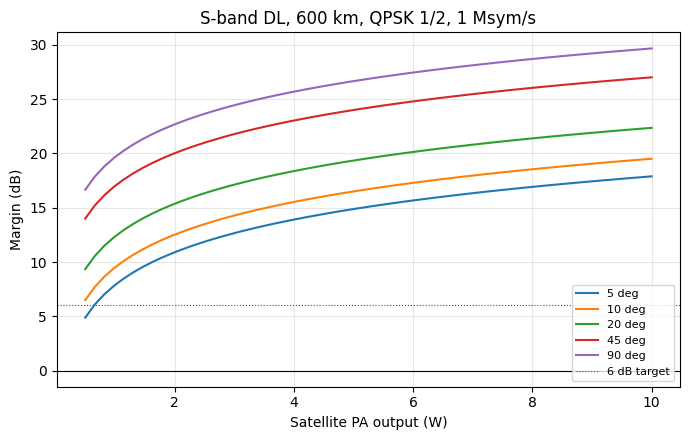

In [ ]:
# PA power needed for a 6 dB margin with the baseline MODCOD / symbol rate
target = 6.0
rows = []
for h in altitudes_km:
    row = dict(alt_km=h)
    for e in (5, 10, 20, 30):
        need_W = SAT_S["pa_out_W"]*10**((target - margin_S_dB(h, e))/10)
        row[f"{e}deg_W"] = need_W
    rows.append(row)
print(f"Sat PA output [W] needed for {target} dB margin, {DVB_S2['modcod']}, {DVB_S2['Rs_sps']/1e6:g} Msym/s")
print(pd.DataFrame(rows).round(2).to_string(index=False))

# Margin vs PA power at 600 km
P_W = np.linspace(0.5, 10, 60)
fig, ax = plt.subplots(figsize=(7,4.5))
for e in (5, 10, 20, 45, 90):
    base = margin_S_dB(600, e)
    ax.plot(P_W, base + 10*np.log10(P_W/SAT_S["pa_out_W"]), label=f"{e} deg")
ax.axhline(0, color="k", lw=0.8); ax.axhline(6, color="r", ls=":", lw=0.8, label="6 dB target")
ax.set_xlabel("Satellite PA output (W)"); ax.set_ylabel("Margin (dB)")
ax.set_title(f"S-band DL, 600 km, {DVB_S2['modcod']}, {DVB_S2['Rs_sps']/1e6:g} Msym/s")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


S-band Monte Carlo:

- sat_ant_std: tumbling patch, peak-to-average swing. If the satellite is NOT pointing the patch at the ground during passes, this normal spread is far too kind: a patch's back side is 15–20 dB down.
- dish_gain_std: modelled, not measured, dish efficiency.
- point_std: dish pointing (clipped at 0 dB).
- tsys_std: GS system temperature spread.
- Polarization fixed at 3 dB (linear patch into circular feed).


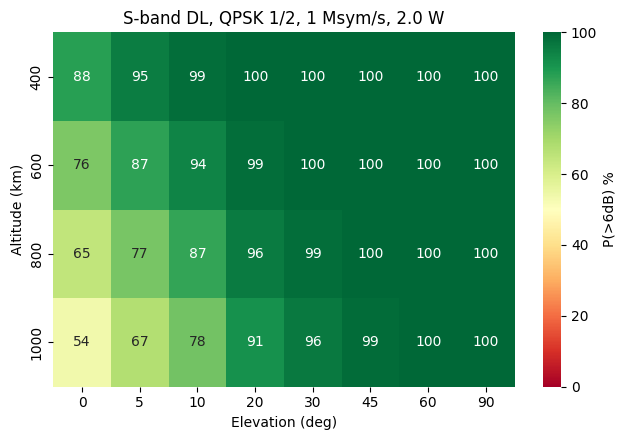

        0     5     10    20     30     45     60     90
400   88.0  95.4  98.6  99.9  100.0  100.0  100.0  100.0
600   76.3  87.3  93.8  98.8   99.8  100.0  100.0  100.0
800   64.6  77.3  86.6  95.8   98.8   99.8   99.9  100.0
1000  53.9  67.2  77.8  91.1   96.5   99.1   99.7   99.9


In [ ]:
def monte_carlo_margin_S(alt_km, elev_deg, modcod=None, n=20000, seed=0,
                         sat_ant_std_dB=3.0, dish_gain_std_dB=1.0, point_std_dB=2.5,
                         tsys_std_K=30.0, pa_std_dB=0.5, atm_std_dB=0.1):
    rng = np.random.default_rng(seed)
    s = spec_DL_S
    ov = dict(   # every randomized term is actually passed into the link equation
        tx_power_dBm = s["tx_power_dBm"] + rng.normal(0, pa_std_dB, n),
        tx_gain_dBi  = s["tx_gain_dBi"]  + rng.normal(0, sat_ant_std_dB, n),
        rx_gain_dBi  = s["rx_gain_dBi"]  + rng.normal(0, dish_gain_std_dB, n),
        L_point_dB   = loss_sample(rng, s["L_point_dB"], point_std_dB, n),
        L_atm_dB     = s["L_atm_dB"] + np.abs(rng.normal(0, atm_std_dB, n)),
    )
    tsys = np.clip(s["T_sys_K"] + rng.normal(0, tsys_std_K, n), 30, None)
    return prx_dBm(alt_km, elev_deg, s, f_Hz_S, **ov) - dvbs2_required_dBm(tsys, modcod)

p6_s = p_target_grid(altitudes_km, elevations_degree, monte_carlo_margin_S)
plot_heatmaps([p6_s], [f"S-band DL, {DVB_S2['modcod']}, {DVB_S2['Rs_sps']/1e6:g} Msym/s, {SAT_S['pa_out_W']} W"])
print(p6_s.round(1).to_string())


##Wavelength

The RF wavelength is:

$$
\lambda = \frac{c}{f}
$$

where:

- $\lambda$ = wavelength [m]
- $c$ = speed of light [m/s]
- $f$ = carrier frequency [Hz]



#Slant Range for a LEO Satellite

For a satellite at altitude $h$ and elevation angle $\epsilon$:

$$
d =
\sqrt{
(R_E+h)^2
-
R_E^2\cos^2\epsilon
}
-
R_E\sin\epsilon
$$

where:

- $d$ = satellite-to-ground slant range
- $R_E$ = Earth radius
- $h$ = satellite altitude
- $\epsilon$ = elevation angle


At zenith:

$$
\epsilon = 90^\circ
$$

so:

$$
d=h
$$

At the horizon:

$$
\epsilon = 0^\circ
$$

so:

$$
d =
\sqrt{(R_E+h)^2-R_E^2}
$$
